# Naive Bayes dự đoán hành vi mua hàng

Dữ liệu Customer Behaviour gồm giới tính, tuổi, mức lương ước tính và nhãn `Purchased`. Dùng Gaussian Naive Bayes cho các thuộc tính số sau khi mã hóa giới tính.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay)

DATA_PATH = Path("../data/Customer_Behaviour.csv")
df = pd.read_csv(DATA_PATH)
print(f"Kích thước dữ liệu: {df.shape}")
display(df.head())
print("\nKiểu dữ liệu và giá trị thiếu:")
display(pd.DataFrame({"kiểu dữ liệu": df.dtypes.astype(str), "giá trị thiếu": df.isna().sum()}))


Kích thước dữ liệu: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0



Kiểu dữ liệu và giá trị thiếu:


,kiểu dữ liệu,giá trị thiếu
User ID,int64,0
Gender,str,0
Age,int64,0
EstimatedSalary,int64,0
Purchased,int64,0


## Khám phá dữ liệu và chia tập

In [2]:
TARGET = "Purchased"
print("Phân bố nhãn:")
display(df[TARGET].value_counts(dropna=False).to_frame("số lượng"))
print("\nThống kê thuộc tính số:")
display(df.select_dtypes(include="number").describe().T)
df_model = df.dropna(subset=[TARGET]).copy()
X = df_model.drop(columns=[TARGET]).drop(columns=["User ID"], errors="ignore")
if "Gender" in X.columns:
    X["Gender"] = X["Gender"].map({"Female": 0, "Male": 1})
y = df_model[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)


Phân bố nhãn:


,số lượng
Purchased,
0,257
1,143



Thống kê thuộc tính số:


,count,mean,std,min,25%,50%,75%,max
User ID,400.0,1.569154e+07,71658.321581,15566689.0,15626763.75,15694341.5,15750363.0,15815236.0
Age,400.0,3.765500e+01,10.482877,18.0,29.75,37.0,46.0,60.0
EstimatedSalary,400.0,6.974250e+04,34096.960282,15000.0,43000.00,70000.0,88000.0,150000.0
Purchased,400.0,3.575000e-01,0.479864,0.0,0.00,0.0,1.0,1.0


Train: (320, 3) Test: (80, 3)


## Huấn luyện Gaussian Naive Bayes

GaussianNB mô hình hóa phân bố của các thuộc tính số trong từng lớp. Bước điền giá trị thiếu được đặt trong pipeline.

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
model = make_pipeline(SimpleImputer(strategy="median"), GaussianNB())
model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('gaussiannb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Gender','Age','EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be 

## Đánh giá mô hình

Dữ liệu kiểm tra được giữ riêng khỏi quá trình huấn luyện. Báo cáo precision, recall, F1 và ma trận nhầm lẫn cho từng lớp.

Accuracy: 0.875

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.90        51
           1       0.85      0.79      0.82        29

    accuracy                           0.88        80
   macro avg       0.87      0.86      0.86        80
weighted avg       0.87      0.88      0.87        80



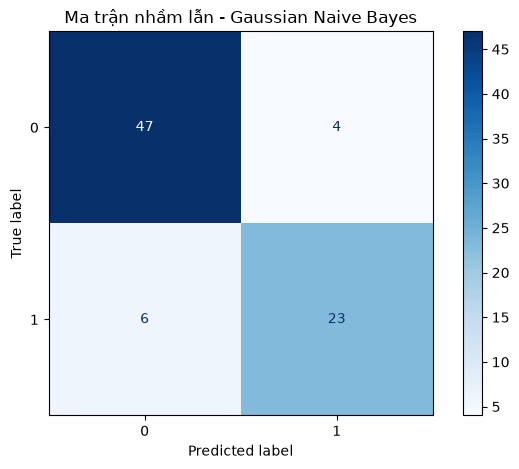

In [4]:
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", values_format="d")
plt.title("Ma trận nhầm lẫn - Gaussian Naive Bayes")
plt.tight_layout()
plt.show()


## Nhận xét

Dựa trên classification report và ma trận nhầm lẫn ở trên, hãy nhận xét mô hình phân loại **Purchased** tốt đến đâu, đặc biệt chú ý lớp ít xuất hiện và các trường hợp dự đoán sai.